# Mushroom Classification: Edible or Poisonous?
**Information Systems — Group Project**

## 1. Introduction
This project investigates whether observable mushroom characteristics can predict whether a mushroom is edible or poisonous. We compare an entropy-based Decision Tree with K-Nearest Neighbours (KNN), examine informative features, and evaluate the effect of model complexity on generalisation.

Research questions:
- Which categorical characteristics provide the most information about mushroom class?
- How does tree depth affect training and validation performance?
- How do Decision Tree and KNN compare on unseen observations?
- How frequently are poisonous mushrooms incorrectly classified as edible?

This is an educational classification experiment, not a tool for deciding whether wild mushrooms are safe to eat.

## 2. Library imports
Import packages for data manipulation, visualisation, preprocessing and model evaluation. A fixed random seed makes the data split reproducible.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.metrics import (mutual_info_score, accuracy_score, recall_score,
                             classification_report, ConfusionMatrixDisplay, confusion_matrix,
                             make_scorer, f1_score)
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.neighbors import KNeighborsClassifier
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.base import clone

SEED = 42

## 3. Data understanding
Load the semicolon-separated dataset and inspect its dimensions, data types and numerical summaries. The target `class` uses `e` for edible and `p` for poisonous.

In [2]:
df = pd.read_csv("secondary_data.csv", sep=";")
print("Dataset shape:", df.shape)
display(df.head())
df.info()
display(df.describe())
display(df["class"].value_counts(dropna=False))

Dataset shape: (61069, 21)


,class,cap-diameter,cap-shape,cap-surface,cap-color,does-bruise-or-bleed,gill-attachment,gill-spacing,gill-color,stem-height,...,stem-root,stem-surface,stem-color,veil-type,veil-color,has-ring,ring-type,spore-print-color,habitat,season
0,p,15.26,x,g,o,f,e,NaN,w,16.95,...,s,y,w,u,w,t,g,NaN,d,w
1,p,16.60,x,g,o,f,e,NaN,w,17.99,...,s,y,w,u,w,t,g,NaN,d,u
2,p,14.07,x,g,o,f,e,NaN,w,17.80,...,s,y,w,u,w,t,g,NaN,d,w
3,p,14.17,f,h,e,f,e,NaN,w,15.77,...,s,y,w,u,w,t,p,NaN,d,w
4,p,14.64,x,h,o,f,e,NaN,w,16.53,...,s,y,w,u,w,t,p,NaN,d,w


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 61069 entries, 0 to 61068
Data columns (total 21 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   class                 61069 non-null  object 
 1   cap-diameter          61069 non-null  float64
 2   cap-shape             61069 non-null  object 
 3   cap-surface           46949 non-null  object 
 4   cap-color             61069 non-null  object 
 5   does-bruise-or-bleed  61069 non-null  object 
 6   gill-attachment       51185 non-null  object 
 7   gill-spacing          36006 non-null  object 
 8   gill-color            61069 non-null  object 
 9   stem-height           61069 non-null  float64
 10  stem-width            61069 non-null  float64
 11  stem-root             9531 non-null   object 
 12  stem-surface          22945 non-null  object 
 13  stem-color            61069 non-null  object 
 14  veil-type             3177 non-null   object 
 15  veil-color         

,cap-diameter,stem-height,stem-width
count,61069.000000,61069.000000,61069.000000
mean,6.733854,6.581538,12.149410
std,5.264845,3.370017,10.035955
min,0.380000,0.000000,0.000000
25%,3.480000,4.640000,5.210000
50%,5.860000,5.950000,10.190000
75%,8.540000,7.740000,16.570000
max,62.340000,33.920000,103.910000


class
p    33888
e    27181
Name: count, dtype: int64

## 4. Data quality and cleaning
Check for missing values and remove duplicate records to prevent identical observations from appearing in both the training and test sets. Remove records with missing or invalid class labels. Missing values in other features are kept and will be handled during preprocessing. Features with more than 80% missing values are removed because they contain very limited information. The 80% threshold is a practical choice rather than a statistically proven optimal value.

,Missing count,Missing %
veil-type,57892,94.797688
spore-print-color,54715,89.595376
veil-color,53656,87.861272
stem-root,51538,84.393064
stem-surface,38124,62.427746
gill-spacing,25063,41.040462
cap-surface,14120,23.121387
gill-attachment,9884,16.184971
ring-type,2471,4.046243
cap-color,0,0.000000


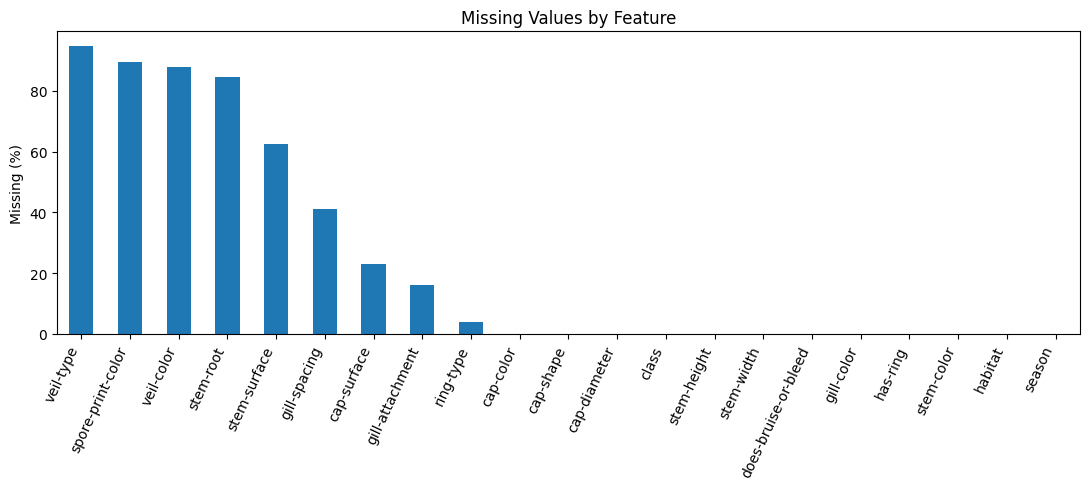

Exact duplicates: 146
Invalid or missing labels: 0
Cleaned shape: (60923, 21)


In [3]:
missing_summary = pd.DataFrame({"Missing count": df.isna().sum(),
                                "Missing %": df.isna().mean()*100}).sort_values("Missing %", ascending=False)
display(missing_summary)
missing_summary["Missing %"].plot.bar(figsize=(11,5))
plt.ylabel("Missing (%)")
plt.title("Missing Values by Feature")
plt.xticks(rotation=65, ha="right")
plt.tight_layout(); plt.show()
print("Exact duplicates:", df.duplicated().sum())
print("Invalid or missing labels:", (~df["class"].isin(["e", "p"])).sum())
df_clean = df.loc[df["class"].isin(["e", "p"])].drop_duplicates().copy()
print("Cleaned shape:", df_clean.shape)

## 5. Data partitioning
Split the dataset into 80% for training and 20% for final testing. Stratified sampling ensures that the proportions of edible and poisonous mushrooms remain similar in both sets. Only the training data is used for model development and parameter tuning. Feature removal and missing value imputation are performed separately within each cross-validation fold to prevent data leakage.

In [6]:
train_df, test_df = train_test_split(df_clean, test_size=0.2, random_state=SEED,
                                    stratify=df_clean["class"])
X_train = train_df.drop(columns="class")
X_test = test_df[X_train.columns]
y_train, y_test = train_df["class"], test_df["class"]
print("Training:", X_train.shape, "Test:", X_test.shape)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

Training: (48738, 20) Test: (12185, 20)


## 6. Exploratory data analysis
### 6.1 Class distribution
Examine whether one class dominates the training dataset. Accuracy alone may conceal poor performance on an underrepresented class.

,Count,Percentage
class,,
Poisonous,26993,55.383889
Edible,21745,44.616111


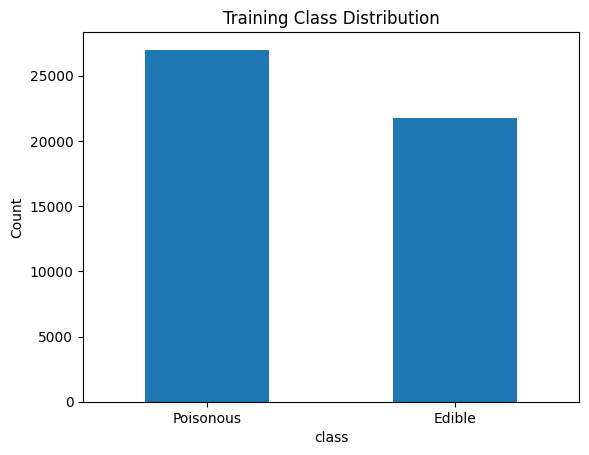

In [7]:
counts = y_train.value_counts().rename({"e":"Edible", "p":"Poisonous"})
display(pd.DataFrame({"Count":counts, "Percentage":100*counts/counts.sum()}))
counts.plot.bar(rot=0); plt.title("Training Class Distribution"); plt.ylabel("Count"); plt.show()

### 6.2 Cap shape and toxicity
Compare the proportion of poisonous mushrooms within each cap-shape category. Group counts are included because small categories may produce unstable percentages.

,size,Poisonous %
shape,,
Bell,4542,77.917217
Conical,1444,58.518006
Convex,21566,51.799128
Flat,10746,51.470315
Other,2646,75.396825
Spherical,2075,40.192771
Sunken,5719,53.820598


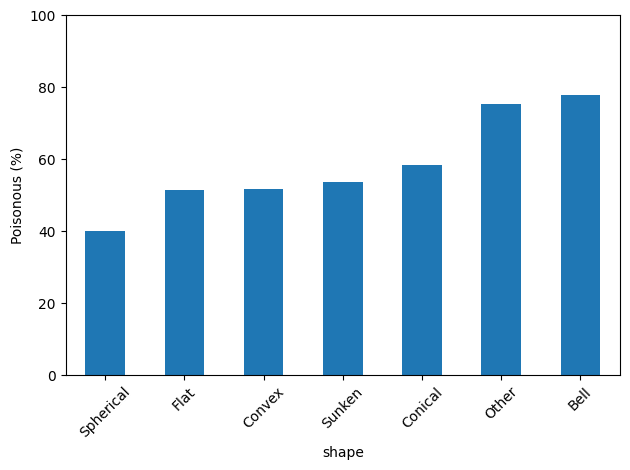

In [8]:
labels = {"b":"Bell", "c":"Conical", "x":"Convex", "f":"Flat", "s":"Sunken", "p":"Spherical", "o":"Other"}
shape = train_df["cap-shape"].map(labels).fillna(train_df["cap-shape"]).fillna("Missing")
summary = train_df.assign(shape=shape, poisonous=y_train.eq("p")).groupby("shape")["poisonous"].agg(["size","mean"])
summary["Poisonous %"] = 100*summary.pop("mean")
display(summary)
summary["Poisonous %"].sort_values().plot.bar(rot=45)
plt.ylabel("Poisonous (%)"); plt.ylim(0,100); plt.tight_layout(); plt.show()

### 6.3 Cap diameter and toxicity
Compare medians, variability and overlap using boxplots. Overlap would suggest that diameter alone is insufficient for reliable classification.

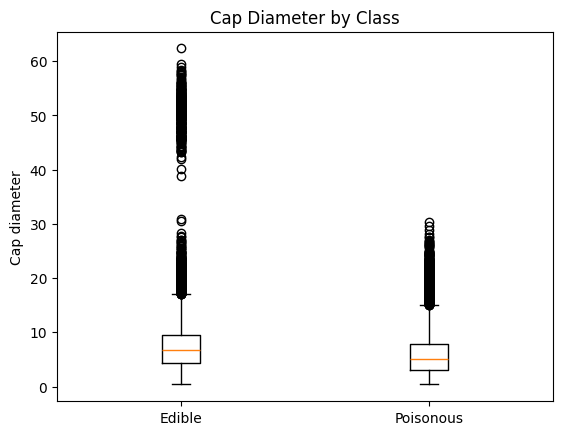

In [9]:
groups = [train_df.loc[y_train.eq(label), "cap-diameter"].dropna() for label in ["e","p"]]
plt.boxplot(groups); plt.xticks([1,2],["Edible","Poisonous"])
plt.ylabel("Cap diameter"); plt.title("Cap Diameter by Class"); plt.show()

## 7. Information gain
Information gain measures the reduction in target entropy after observing a feature: $IG(Y,X)=H(Y)-H(Y|X)$. Mutual information is converted from natural-log units to bits. This analysis covers categorical features only and is descriptive; it does not select model inputs. High-cardinality features may receive inflated scores.

,Information gain (bits)
stem-surface,0.060762
stem-color,0.058537
cap-color,0.045086
cap-surface,0.043601
ring-type,0.041352
gill-attachment,0.035838
cap-shape,0.027279
gill-color,0.026700
habitat,0.026282
season,0.010276


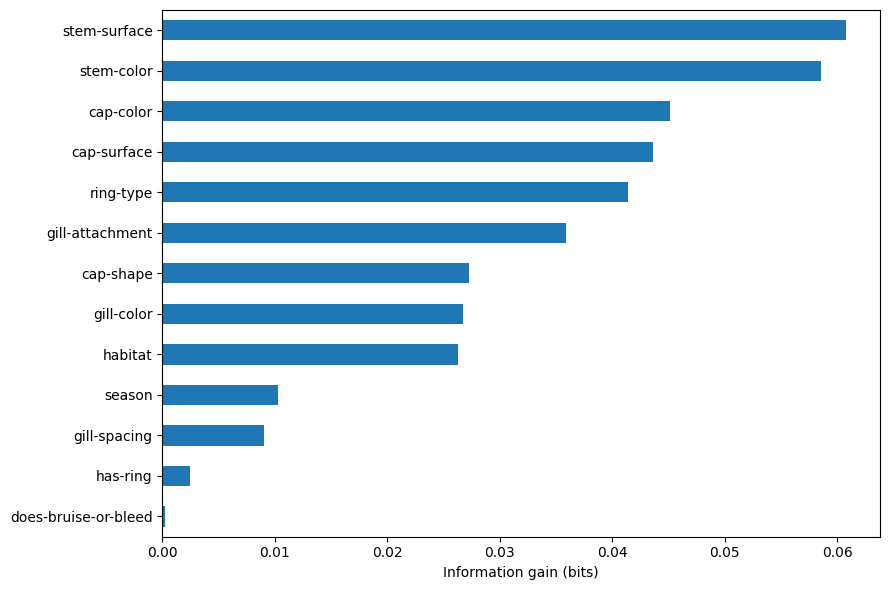

In [10]:
cat_cols = X_train.select_dtypes(exclude="number").columns
ig = pd.Series({col: mutual_info_score(X_train[col].fillna("Missing"), y_train)/np.log(2)
                for col in cat_cols if X_train[col].isna().mean() <= .8}).sort_values(ascending=False)
display(ig.to_frame("Information gain (bits)"))
ig.sort_values().plot.barh(figsize=(9,6)); plt.xlabel("Information gain (bits)"); plt.tight_layout(); plt.show()

## 8. Model preprocessing
Features with more than 80% missing values are removed based on the training data in each cross-validation fold. Missing numerical values are replaced with the median, while missing categorical values are treated as a separate category. Categorical variables are then converted into numerical format using one-hot encoding. For KNN, numerical variables are also standardised to ensure that differences in scale do not unfairly influence distance calculations. Decision Trees do not require standardisation because they split data based on feature values rather than distances.

In [11]:
def numeric_columns(X):
    return [col for col in X.select_dtypes(include="number") if X[col].isna().mean() <= .8]

def categorical_columns(X):
    return [col for col in X.select_dtypes(exclude="number") if X[col].isna().mean() <= .8]

def preprocessing(scale=False):
    steps = [("imputer", SimpleImputer(strategy="median"))]
    if scale:
        steps.append(("scaler", StandardScaler()))
    return ColumnTransformer([
        ("num", Pipeline(steps), numeric_columns),
        ("cat", Pipeline([("imputer", SimpleImputer(strategy="constant", fill_value="Missing")),
                          ("encoder", OneHotEncoder(handle_unknown="ignore"))]), categorical_columns)
    ])

def tree(depth, weights=None):
    return Pipeline([("preprocess", preprocessing()),
                     ("classifier", DecisionTreeClassifier(criterion="entropy", max_depth=depth,
                                                           class_weight=weights, random_state=SEED))])

def knn(k):
    return Pipeline([("preprocess", preprocessing(scale=True)),
                     ("classifier", KNeighborsClassifier(n_neighbors=k, n_jobs=-1))])

scoring = {"accuracy":"accuracy", "poisonous_recall":make_scorer(recall_score, pos_label="p")}

def tune(factory, values, parameter):
    rows = []
    for value in values:
        scores = cross_validate(factory(value), X_train, y_train, cv=cv,
                                scoring=scoring, return_train_score=True)
        rows.append({parameter:value, "Training accuracy":scores["train_accuracy"].mean(),
                     "Validation accuracy":scores["test_accuracy"].mean(),
                     "Validation SD":scores["test_accuracy"].std(),
                     "Poisonous recall":scores["test_poisonous_recall"].mean()})
    return pd.DataFrame(rows)

## 9. Decision Tree
### 9.1 Baseline
Use entropy as the splitting criterion and a maximum depth of five as an initial complexity constraint. Evaluate the baseline with five-fold cross-validation rather than using the test set.

In [12]:
baseline = cross_validate(tree(5), X_train, y_train, cv=cv, scoring=scoring)
print("Baseline validation accuracy:", baseline["test_accuracy"].mean())
print("Baseline poisonous recall:", baseline["test_poisonous_recall"].mean())

Baseline validation accuracy: 0.7253068471474805
Baseline poisonous recall: 0.6004149836044042


### 9.2 Tree depth and overfitting
Increasing depth allows more complex rules. A widening gap between training and validation accuracy may indicate overfitting. Select depth by mean validation accuracy, preferring the smaller depth in an exact tie. This is pre-pruning.

,Depth,Training accuracy,Validation accuracy,Validation SD,Poisonous recall
0,1,0.608606,0.607883,0.003199,0.531620
1,2,0.650688,0.650109,0.003191,0.525025
2,3,0.679839,0.679101,0.004036,0.584300
3,4,0.690770,0.689995,0.004171,0.526655
4,5,0.725435,0.725307,0.003276,0.600415
5,6,0.738397,0.737412,0.002523,0.627682
6,7,0.753232,0.752780,0.002330,0.627978
7,8,0.775263,0.773996,0.009109,0.948023
8,9,0.793677,0.791333,0.006947,0.697107
9,10,0.845957,0.845501,0.011532,0.744713


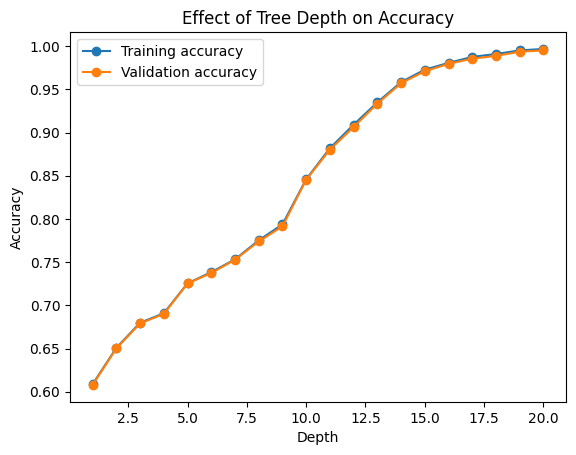

Selected depth: 20


In [13]:
tree_results = tune(tree, range(1,21), "Depth")
display(tree_results)
tree_results.plot(x="Depth", y=["Training accuracy","Validation accuracy"], marker="o")
plt.title("Effect of Tree Depth on Accuracy"); plt.ylabel("Accuracy"); plt.show()
best_depth = int(tree_results.loc[tree_results["Validation accuracy"].idxmax(), "Depth"])
print("Selected depth:", best_depth)

## 10. K-Nearest Neighbours
KNN predicts the class using nearby training observations. Small k may be sensitive to noise, whereas large k may smooth away useful patterns. Compare candidate values using the same cross-validation folds as the Decision Tree. This may take several minutes for a large dataset.

,k,Training accuracy,Validation accuracy,Validation SD,Poisonous recall
0,1,1.000000,1.000000,0.000000,1.000000
1,3,0.999995,0.999979,0.000041,1.000000
2,5,0.999979,0.999979,0.000041,1.000000
3,7,0.999979,0.999979,0.000041,1.000000
4,9,0.999938,0.999856,0.000139,1.000000
5,11,0.999867,0.999774,0.000176,1.000000
6,15,0.999687,0.999672,0.000151,0.999963


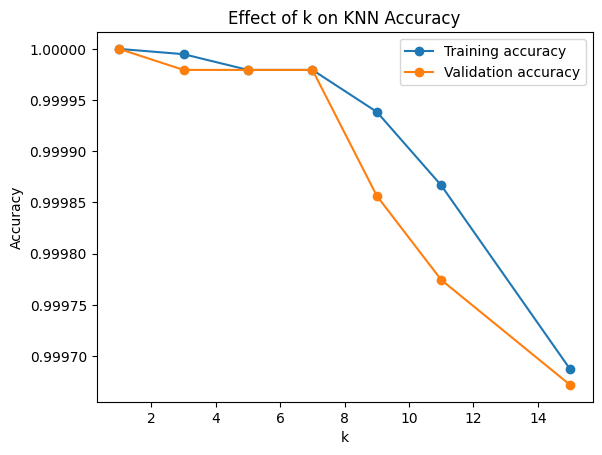

Selected k: 1


In [18]:
knn_results = tune(knn, [1,3,5,7,9,11,15], "k")
display(knn_results)
knn_results.plot(x="k", y=["Training accuracy","Validation accuracy"], marker="o")
plt.ylabel("Accuracy"); plt.title("Effect of k on KNN Accuracy"); plt.show()
best_k = int(knn_results.loc[knn_results["Validation accuracy"].idxmax(), "k"])
print("Selected k:", best_k)

## 11. Misclassification risk
Treat poisonous as the positive class. A false negative (poisonous predicted edible) is more consequential than a false positive (edible predicted poisonous). As an illustrative sensitivity experiment, compare Decision Trees assigning poisonous observations weights of 1, 2, 5 and 10. These weights are hypothetical, not measured real-world costs. Select the weighted alternative by validation poisonous recall, breaking ties by accuracy and then lower weight. This is separate from the accuracy-optimised baseline comparison.

In [15]:
risk_results = tune(lambda w: tree(best_depth, {"e":1,"p":w}), [1,2,5,10], "Poisonous weight")
display(risk_results)
best_weight = int(risk_results.sort_values(["Poisonous recall","Validation accuracy","Poisonous weight"], ascending=[False,False,True]).iloc[0]["Poisonous weight"])
print("Selected weight:", best_weight)

,Poisonous weight,Training accuracy,Validation accuracy,Validation SD,Poisonous recall
0,1,0.996871,0.995199,0.003080,0.993146
1,2,0.996933,0.995117,0.001800,0.997370
2,5,0.999287,0.997825,0.000647,0.998777
3,10,0.999097,0.997805,0.001437,0.999259


Selected weight: 10


## 12. Final model evaluation
Fit the selected configurations on all training data and evaluate them on the same held-out test set. Report accuracy, poisonous recall, poisonous F1 and both types of errors. Do not use these test results to retune the models.

In [16]:
models = {"Decision Tree":tree(best_depth), "KNN":knn(best_k),
          "Risk-weighted Tree":tree(best_depth, {"e":1,"p":best_weight})}
results = []
for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    tn, fp, fn, tp = confusion_matrix(y_test, pred, labels=["e","p"]).ravel()
    results.append({"Model":name, "Accuracy":accuracy_score(y_test,pred),
                    "Poisonous recall":recall_score(y_test,pred,pos_label="p"),
                    "Poisonous F1":f1_score(y_test,pred,pos_label="p"),
                    "False positives":fp, "False negatives":fn})
    print(name)
    print(classification_report(y_test,pred,labels=["e","p"],target_names=["Edible","Poisonous"]))
    ConfusionMatrixDisplay.from_predictions(y_test,pred,labels=["e","p"],display_labels=["Edible","Poisonous"])
    plt.title(name); plt.show()
comparison = pd.DataFrame(results).set_index("Model")
display(comparison)

NameError: name 'best_k' is not defined

### 12.1 Decision Tree visualisation
Display the first three levels of the selected unweighted tree to illustrate its decision rules. The fitted tree may extend beyond the displayed levels.

In [17]:
best_tree = models["Decision Tree"]
classifier = best_tree.named_steps["classifier"]
plt.figure(figsize=(18,9))
plot_tree(classifier, feature_names=best_tree.named_steps["preprocess"].get_feature_names_out(),
          class_names=[{"e":"Edible","p":"Poisonous"}[x] for x in classifier.classes_],
          filled=True, rounded=True, max_depth=3, fontsize=8)
plt.tight_layout(); plt.show()

NameError: name 'models' is not defined

## 13. Discussion and conclusion
Complete this section after running the notebook. Do not report results that have not been observed.

- **Data quality:** Which features had substantial missingness, and how many duplicate records were removed?
- **Exploratory findings:** Which cap shapes had higher poisonous proportions? How much did cap diameters overlap?
- **Information gain:** Which categorical features ranked highest, and what might explain their predictive relevance?
- **Overfitting:** At what depth did validation accuracy peak? Did the training-validation gap increase?
- **Model comparison:** Which model achieved the highest test accuracy and which had the highest poisonous recall?
- **Risk trade-off:** Did weighting reduce false negatives, and at what cost in false positives or overall accuracy?

### Limitations
The missingness threshold and class weights are heuristic. One-hot encoding and numerical scaling affect KNN distances. Random splitting may overestimate generalisation if related or near-duplicate observations occur across partitions. External validation would be required before any practical use. No model in this notebook establishes that a mushroom is safe to consume.